In [1]:
import flopy
import numpy as np
import matplotlib.pyplot as plt
import xmf6
from src_02 import vis
from src_04 import utils

In [2]:
# Usamos LaTeX para los textos de la figura.
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Computer Modern Roman"],
})

In [3]:
paths = dict(
    # Archivo con las concentraciones iniciales de las componentes
    u_init = "io_wma/u_init.dat",
)
_, species = utils.initial_conditions(paths, comp = False, spec=True)
nspec = len(species["names"])

xmf6.nice_print("Species", species)


Species
―――――――
    names = ―― INIT names ――
          = h+
          = cl-
          = no3-
          = n2(aq)(p)
          = ch2o(aq)
          = hco3-
          = o2(aq)
          = co3-2
          = ―― END names ――
init_conc = ―― INIT init_conc ――
          = [1.e-07 1.e-07 1.e-07 1.e-07 1.e-07 1.e-07 1.e-07 1.e-07 1.e-07 1.e-07]
          = [1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16]
          = [1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05]
          = [1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16 1.e-16]
          = [1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05 1.e-05]
          = [0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001]
          = [1.e-06 1.e-06 1.e-06 1.e-06 1.e-06 1.e-06 1.e-06 1.e-06 1.e-06 1.e-06]
          = [4.69029e-07 4.69029e-07 4.69029e-07 4.69029e-07 4.69029e-07 4.69029e-07
 4.69029e-07 4.69029e-07 4.69029e-07 4.69029e-07]
          = ―― END init_conc ――
ex

In [4]:
o_sim_list = []
o_gwt_list = []
cspec_list = []
for i in range(1, 9):
    # Cargamos los modelos de transporte
    o_sim_list.append(flopy.mf6.MFSimulation.load(sim_ws=f"io_mf6/gwt{i}", verbosity_level=0))
    
    # Obtenemos los objetos de los modelos
    o_gwt_list.append(o_sim_list[i-1].get_model(f"transport{i}"))

    # Objetos para recuperar la concentración
    cspec_list.append(o_gwt_list[i-1].output.concentration())


In [5]:
# Recuperamos las coordenadas del dominio a partir de uno de los modelos
grid = o_gwt_list[0].modelgrid

# Recuperamos las coordenadas de los centros de las celdas de la malla
x = grid.xcellcenters[0] # centros de los volúmenes
print(x)

# Recuperamos los pasos de tiempo
times = np.asarray(cspec_list[0].get_times())

print(times[::10])

# Recuperamos la concentración
c_list = []

for n, c in enumerate(cspec_list):
    c_array = np.empty((len(times)+1, len(x)), dtype=float)
    c_array[0] = species['init_conc'][n] # Condición inicial
    c_array[1:] = c.get_alldata()[:, 0, 0, :]
    
    c_list.append(c_array)

[0.05 0.15 0.25 0.35 0.45 0.55 0.65 0.75 0.85 0.95]
[0.01 0.11 0.21 0.31 0.41 0.51 0.61 0.71 0.81 0.91 1.01 1.11 1.21 1.31
 1.41 1.51 1.61 1.71 1.81 1.91 2.01 2.11 2.21 2.31 2.41 2.51 2.61 2.71
 2.81 2.91 3.01 3.11 3.21 3.31 3.41 3.51 3.61 3.71 3.81 3.91 4.01 4.11
 4.21 4.31 4.41 4.51 4.61 4.71 4.81 4.91]


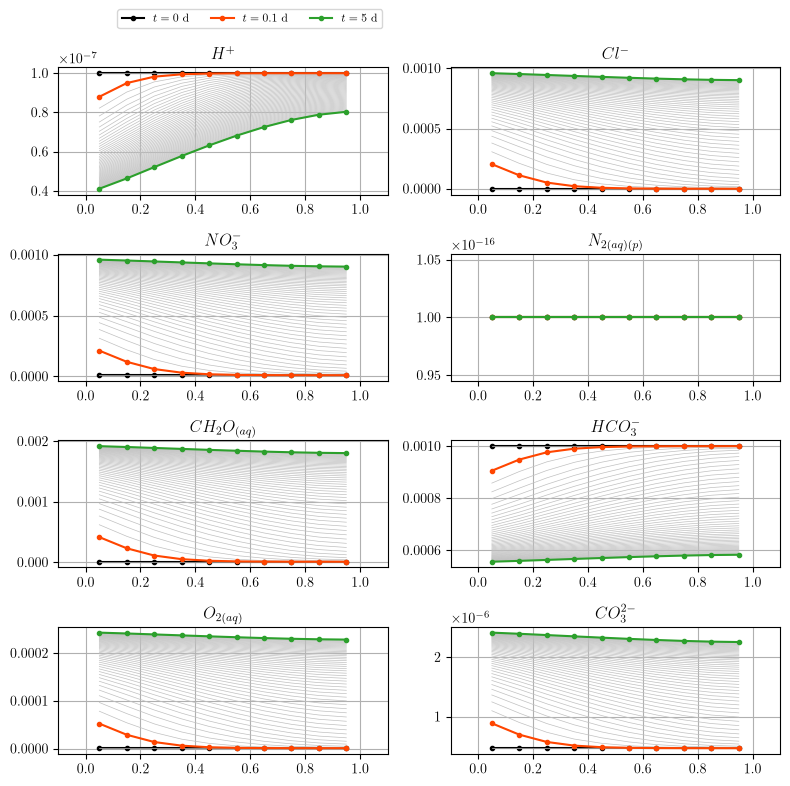

In [6]:
species_names = ["$H^+$", 
                 "$Cl^-$", 
                 "$NO_3^-$",
                 "$N_{2(aq)(p)}$", 
                 "$CH_2O_{(aq)}$", 
                 "$HCO_3^-$", 
                 "$O_{2(aq)}$", 
                 "$CO_3^{2-}$"]

fig, axes = plt.subplots(4, 2, figsize=(8, 8))
ax = axes.flat

tsel = 10
tdays = tsel / 100

for m, c in enumerate(c_list):

    ax[m].plot(x, c[0], lw=1.5, ls = "-", marker = ".", color='black', label = "$t = 0$ d")

    for ci in c[::10]:
        ax[m].plot(x, ci, lw=.5, color='silver')

    ax[m].plot(x, c[tsel], lw=1.5, ls = "-", marker = ".", color='orangered', label = f"$t = {tdays}$ d")

    ax[m].plot(x, c[-1], lw=1.5, ls = "-", marker = ".", color='C2',  label = "$t = 5$ d")
    
    ax[m].set_title(f"{species_names[m]}")
#    ax[m].set_yscale("log")
    ax[m].grid()
    ax[m].set_xlim(-0.1,1.1)

ax[0].legend(ncol=3, loc='best', bbox_to_anchor=(1.0, 1.5), fontsize = 8)
plt.tight_layout()
plt.show()



Selecciona una especie
――――――――――――――――――――――
1 = h+
2 = cl-
3 = no3-
4 = n2(aq)(p)
5 = ch2o(aq)
6 = hco3-
7 = o2(aq)
8 = co3-2
――――――――――――――――――――――


 m =  8


8


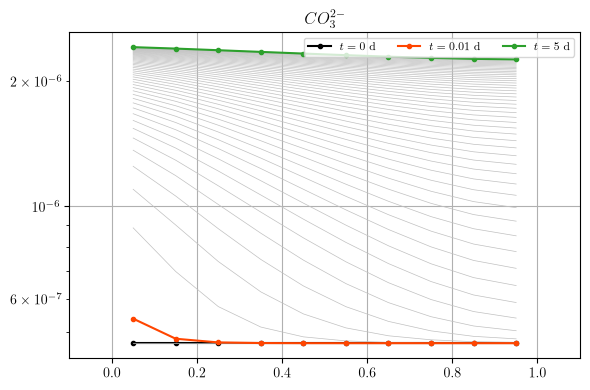

In [7]:
# Seleccionamos una especie.
xmf6.nice_print("Selecciona una especie",
               dict(zip([str(i) for i in range(1, nspec+1)], species["names"])))
m = int(input(" m = ")) - 1
print(m+1)

c = c_list[m]

fig, ax = plt.subplots(1, 1, figsize = (6,4))

tsel = 1
tdays = tsel / 100

ax.plot(x, c[0], lw=1.5, ls = "-", marker = ".", color='black', label = "$t = 0$ d")

for ci in c[::10]:
    ax.plot(x, ci, lw=.5, color='silver')

ax.plot(x, c[tsel], lw=1.5, ls = "-", marker = ".", color='orangered', label = f"$t = {tdays}$ d")

ax.plot(x, c[-1], lw=1.5, ls = "-", marker = ".", color='C2',  label = "$t = 5$ d")
    
ax.set_title(f"{species_names[m]}")
ax.set_yscale("log")
ax.grid()
ax.set_xlim(-0.1,1.1)
ax.legend(ncol=3, loc='best', fontsize = 8)

plt.tight_layout()
plt.show()